In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv
/kaggle/input/datasets/minyingyu/store-sales-time-series-forecastng/holidays_events.csv
/kaggle/input/datasets/minyingyu/store-sales-time-series-forecastng/oil.csv
/kaggle/input/datasets/minyingyu/store-sales-time-series-forecastng/sample_submission.csv
/kaggle/input/datasets/minyingyu/store-sales-time-series-forecastng/stores.csv
/kaggle/input/datasets/minyingyu/store-sales-time-series-forecastng/test.csv
/kaggle/input/datasets/minyingyu/store-sales-time-se

In [2]:
import pandas as pd
base_path='/kaggle/input/datasets/minyingyu/store-sales-time-series-forecastng/'
train=pd.read_csv(base_path+'train.csv', parse_dates=['date'])
test=pd.read_csv(base_path+'test.csv', parse_dates=['date'])
print(f"Training data shape:{train.shape}")

Training data shape:(3000888, 6)


In [3]:
# 1.Define a function to extract time-based and business features.
def create_features(df):
    # Extract month, the day of the month, and the day of the week.
    df['month']=df['date'].dt.month
    df['day']=df['date'].dt.day
    df['dayofweek']=df['date'].dt.dayofweek
    # Business insights: Create a binary feature for Payday (15th and month-end)
    df['is_payday']=((df['day']==15)|df['day']>=28).astype(int)
    return df
# 2.Apply the feature engineering function to both training and test datasets.
train=create_features(train)
test=create_features(test)
# 3.Display the first 5 rows of the newly created features for verification
display(train[['date', 'month', 'day', 'dayofweek', 'is_payday']].head())

,date,month,day,dayofweek,is_payday
0,2013-01-01,1,1,1,0
1,2013-01-01,1,1,1,0
2,2013-01-01,1,1,1,0
3,2013-01-01,1,1,1,0
4,2013-01-01,1,1,1,0


In [4]:
import numpy as np
import lightgbm as lgb
# 1.Select features
features=['store_nbr', 'onpromotion', 'month', 'day', 'dayofweek', 'is_payday']
X_train=train[features].sample(frac=0.1, random_state=42)
y_train=np.log1p(train['sales'].clip(lower=0))[X_train.index]
X_test=test[features]
# 2.Train LightGBM Model
model=lgb.LGBMRegressor(
    n_estimators=150,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
# 3.Generate Predictions
print("Generating predictions")
predictions=model.predict(X_test)
predictions=np.expm1(predictions)
predictions=np.maximum(0, predictions)
# 4.Create Submission File
submission=pd.DataFrame({
    'id':test['id'],
    'sales':predictions
})
submission.to_csv('submission.csv', index=False)
print("Model execution complete. 'Submission.csv' is ready")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007247 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 310
[LightGBM] [Info] Number of data points in the train set: 300089, number of used features: 5
[LightGBM] [Info] Start training from score 2.920591
Generating predictions
Model execution complete. 'Submission.csv' is ready


/tmp/ipykernel_16/197670229.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


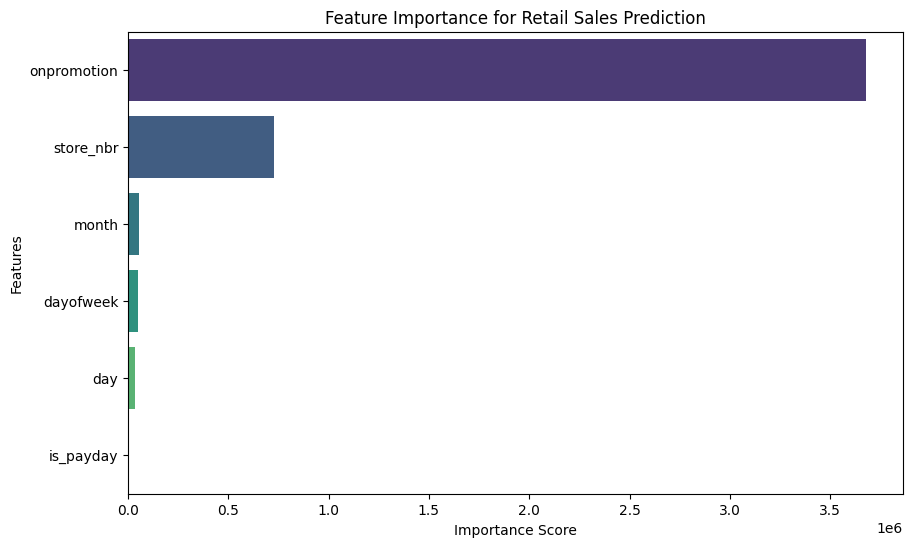

Feature Importance Ranking:


,Feature,Importance
1,onpromotion,3.679613e+06
0,store_nbr,7.299874e+05
2,month,5.559630e+04
4,dayofweek,5.197278e+04
3,day,3.419924e+04
5,is_payday,0.000000e+00


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# 1.Extract feature importance from the trained LightGBM model
importance_df=pd.DataFrame({
    'Feature': features,
    'Importance': model.booster_.feature_importance(importance_type='gain')
})
# 2.Sort the features by importance in descending order
importance_df=importance_df.sort_values(by='Importance', ascending=False)
# 3.Visualize the feature importance
plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title("Feature Importance for Retail Sales Prediction")
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()
# 4.Display the raw importance values
print("Feature Importance Ranking:")
display(importance_df)